# FFT Optimization

Two techniques to improve the THz spectral analysis:

1. **Zero-padding**: Appending zeros on each side → denser frequency-domain sampling (interpolation, not new information)
2. **Spline fitting**: Fit a cubic spline to the EO waveform vs delay, evaluate on a fine grid, then FFT — useful if original sampling is coarse

Primary dataset: 10 nC fine scan `finescaneQ10nC_wh4_0.npz`

In [12]:
import os
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

if os.path.basename(os.getcwd()) == 'Analysis':
    os.chdir('..')

os.makedirs('Results', exist_ok=True)

RF_Hz           = 81.25e6
T_LASER_NS      = 1e9 / RF_Hz
mV              = 1e3
SIGNAL_START_NS = 45.0
SIGNAL_END_NS   = 75.0
FLANK_END_NS    = 100.0
FFT_SIGMA_GHZ   = 0.35
FFT_ORDER       = 6
PROBE_HALF_WIN  = 25

SCANS = [

    {'label': '10 nC',   'Q': 10.0, 'path': 'Data_raw/July31_/finescaneQ10nC_wh4_0.npz'},
]
PRIMARY_PATH = 'Data_raw/July31_/finescaneQ10nC_wh4_0.npz'
print('Setup done. CWD:', os.getcwd())

Setup done. CWD: /home/paulrleaa/Documents/1_Research/Suli2026/SULI_THZ_SUM26


In [13]:
def _period_fill(t_ns, s0, s1):
    dt   = (t_ns[-1]-t_ns[0])/(len(t_ns)-1)
    T    = T_LASER_NS/dt
    i0   = int(round(s0/dt)); i1=int(round(s1/dt))
    idx  = np.arange(i0,i1)
    nl   = np.ceil((idx+1-i0)/T).astype(int); nr=np.ceil((i1-idx)/T).astype(int)
    return i0,i1,np.round(idx-nl*T).astype(int),np.round(idx+nr*T).astype(int)

def fft_lp(res, dt_ns):
    n=res.shape[1]; freqs=np.fft.rfftfreq(n,d=dt_ns)
    filt=np.exp(-0.5*(freqs/FFT_SIGMA_GHZ)**(2*FFT_ORDER))
    return np.fft.irfft(np.fft.rfft(res,axis=1)*filt,n=n,axis=1)

def get_signal(path):
    d=np.load(path); t_ns=1e9*d['x'][0,:]
    phase=d['phase']; delay_ps=(phase-phase[0])/RF_Hz/360*1e12
    dt=(t_ns[-1]-t_ns[0])/(len(t_ns)-1)
    traces=d['BPDwf'].mean(axis=1)
    i0,i1,sl,sr=_period_fill(t_ns,SIGNAL_START_NS,SIGNAL_END_NS)
    bl=traces.copy(); bl[:,i0:i1]=0.5*(traces[:,sl]+traces[:,sr])
    res=fft_lp(traces-bl,dt)
    tp=res.var(axis=0).argmax()
    win=slice(max(0,tp-PROBE_HALF_WIN),min(res.shape[1],tp+PROBE_HALF_WIN))
    sig=res[:,win].mean(axis=1)
    return delay_ps, sig

dp, sig = get_signal(PRIMARY_PATH)
n_orig  = len(sig)
dt_ps   = (dp[-1]-dp[0])/(n_orig-1)
print(f'10 nC scan: {n_orig} steps, dt={dt_ps:.2f} ps, span={dp[-1]-dp[0]:.1f} ps')
print(f'Nyquist = {0.5/dt_ps*1e3:.0f} GHz  |  Δf = {1e3/(n_orig*dt_ps):.1f} GHz')

10 nC scan: 160 steps, dt=0.85 ps, span=135.9 ps
Nyquist = 585 GHz  |  Δf = 7.3 GHz


## Section 1: Baseline FFT

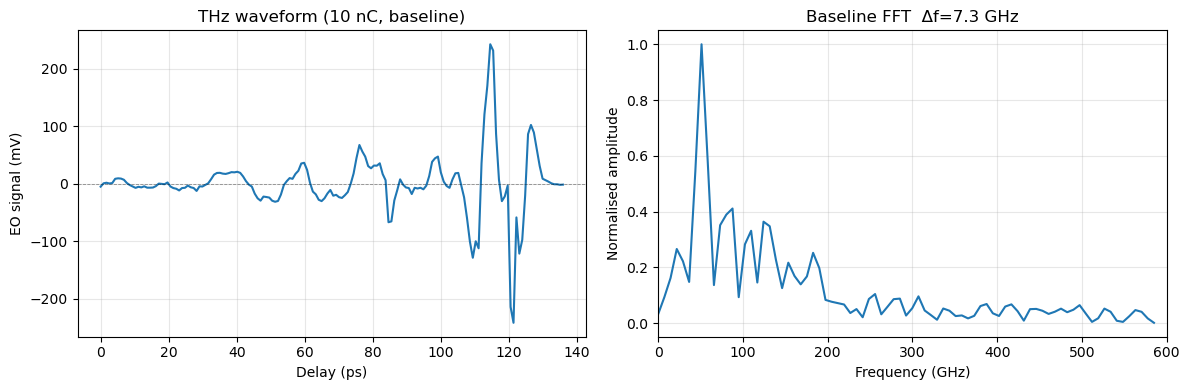

In [14]:
win_h = np.hanning(n_orig)
F0    = np.abs(np.fft.rfft(sig * win_h))
f0    = np.fft.rfftfreq(n_orig, d=dt_ps*1e-12)/1e9  # GHz

fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(dp, mV*sig, 'C0', lw=1.5)
axes[0].axhline(0, color='k', lw=0.6, ls='--', alpha=0.4)
axes[0].set_xlabel('Delay (ps)'); axes[0].set_ylabel('EO signal (mV)')
axes[0].set_title('THz waveform (10 nC, baseline)'); axes[0].grid(True,alpha=0.3)

axes[1].plot(f0, F0/F0.max(), 'C0', lw=1.5)
axes[1].set_xlabel('Frequency (GHz)'); axes[1].set_ylabel('Normalised amplitude')
axes[1].set_title(f'Baseline FFT  Δf={1e3/(n_orig*dt_ps):.1f} GHz')
axes[1].set_xlim(0,600); axes[1].grid(True,alpha=0.3)

plt.tight_layout()
plt.savefig('Results/FFT_baseline.png', dpi=200, bbox_inches='tight')
plt.show()

## Section 2: Zero-Padding Comparison

Zero-padding symmetrically on each side. Hanning window applied to the original signal only, then zero-padded.

In [15]:
# Window the original signal
sig_win = sig * np.hanning(n_orig)

pad_factors = [0, 1, 2, 4, 8]   # N_pad = factor × n_orig on each side (total zeros = 2·fac·N)
colors_pad  = plt.cm.Blues(np.linspace(0.3, 0.95, len(pad_factors)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for fac, col in zip(pad_factors, colors_pad):
    N_pad   = fac * n_orig
    padded  = np.concatenate([np.zeros(N_pad), sig_win, np.zeros(N_pad)])
    F_pad   = np.abs(np.fft.rfft(padded))
    f_pad   = np.fft.rfftfreq(len(padded), d=dt_ps*1e-12)/1e9
    lbl     = f'+{2*fac}N zeros (×{1+2*fac} length)' if fac>0 else 'No padding'
    ax1.plot(f_pad, F_pad/F_pad.max(), color=col, lw=1.2+fac*0.05, label=lbl)
    ax2.plot(f_pad, F_pad/F_pad.max(), color=col, lw=1.2+fac*0.05, label=lbl)

for ax in (ax1, ax2):
    ax.set_xlabel('Frequency (GHz)', fontsize=11)
    ax.set_ylabel('Normalised amplitude', fontsize=11)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
ax1.set_xlim(0,600); ax1.set_title('Zero-padding comparison — full spectrum')
ax2.set_xlim(0,200); ax2.set_title('Zoom: 0–200 GHz')

plt.tight_layout()
plt.savefig('Results/FFT_zero_padding.png', dpi=200, bbox_inches='tight')
plt.show()

KeyboardInterrupt: 

## Section 3: Spline Interpolation (across delay axis)

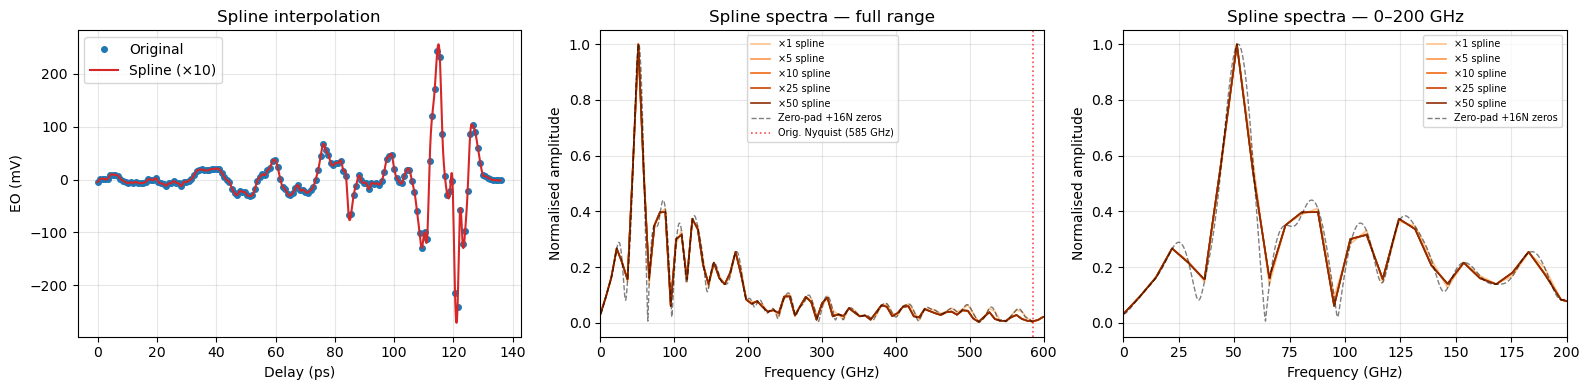

In [ ]:
cs_obj = CubicSpline(dp, sig)

upsample_factors = [1, 5, 10, 25, 50]
colors_sp = plt.cm.Oranges(np.linspace(0.3, 0.95, len(upsample_factors)))

# Original-grid Nyquist — above this, spline-upsampled spectra are interpolation artifact
f_nyq_orig = 0.5/dt_ps * 1e3   # GHz

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Time-domain: original vs spline
dp_fine = np.linspace(dp[0], dp[-1], n_orig*10)
axes[0].plot(dp, mV*sig, 'C0o', ms=4, label='Original')
axes[0].plot(dp_fine, mV*cs_obj(dp_fine), 'C3-', lw=1.5, label='Spline (×10)')
axes[0].set_xlabel('Delay (ps)'); axes[0].set_ylabel('EO (mV)')
axes[0].set_title('Spline interpolation'); axes[0].legend(); axes[0].grid(True,alpha=0.3)

# Spectra for each upsampling factor
for fac, col in zip(upsample_factors, colors_sp):
    n_up   = n_orig * fac
    dp_up  = np.linspace(dp[0], dp[-1], n_up)
    sig_up = cs_obj(dp_up) * np.hanning(n_up)
    F_up   = np.abs(np.fft.rfft(sig_up))
    f_up   = np.fft.rfftfreq(n_up, d=dt_ps*1e-12/fac)/1e9
    axes[1].plot(f_up, F_up/F_up.max(), color=col, lw=1.2, label=f'×{fac} spline')
    axes[2].plot(f_up, F_up/F_up.max(), color=col, lw=1.2, label=f'×{fac} spline')

# Overlay zero-pad reference (8·N zeros each side → +16N zeros total)
padded_ref = np.concatenate([np.zeros(8*n_orig), sig_win, np.zeros(8*n_orig)])
F_ref      = np.abs(np.fft.rfft(padded_ref))
f_ref      = np.fft.rfftfreq(len(padded_ref), d=dt_ps*1e-12)/1e9
axes[1].plot(f_ref, F_ref/F_ref.max(), 'k--', lw=1, alpha=0.5, label='Zero-pad +16N zeros')
axes[2].plot(f_ref, F_ref/F_ref.max(), 'k--', lw=1, alpha=0.5, label='Zero-pad +16N zeros')

# Mark original Nyquist on the full-range panel — content above this is spline artifact
axes[1].axvline(f_nyq_orig, color='red', ls=':', lw=1.2, alpha=0.7,
                label=f'Orig. Nyquist ({f_nyq_orig:.0f} GHz)')

for ax, xlim in zip(axes[1:], [600, 200]):
    ax.set_xlabel('Frequency (GHz)'); ax.set_ylabel('Normalised amplitude')
    ax.set_xlim(0, xlim); ax.legend(fontsize=7); ax.grid(True, alpha=0.3)
axes[1].set_title('Spline spectra — full range')
axes[2].set_title('Spline spectra — 0–200 GHz')

plt.tight_layout()
plt.savefig('Results/FFT_spline_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

## Section 4: Combined Optimized Approach

Recommended workflow: spline ×10 → Hanning window → zero-pad to next power of 2 → FFT

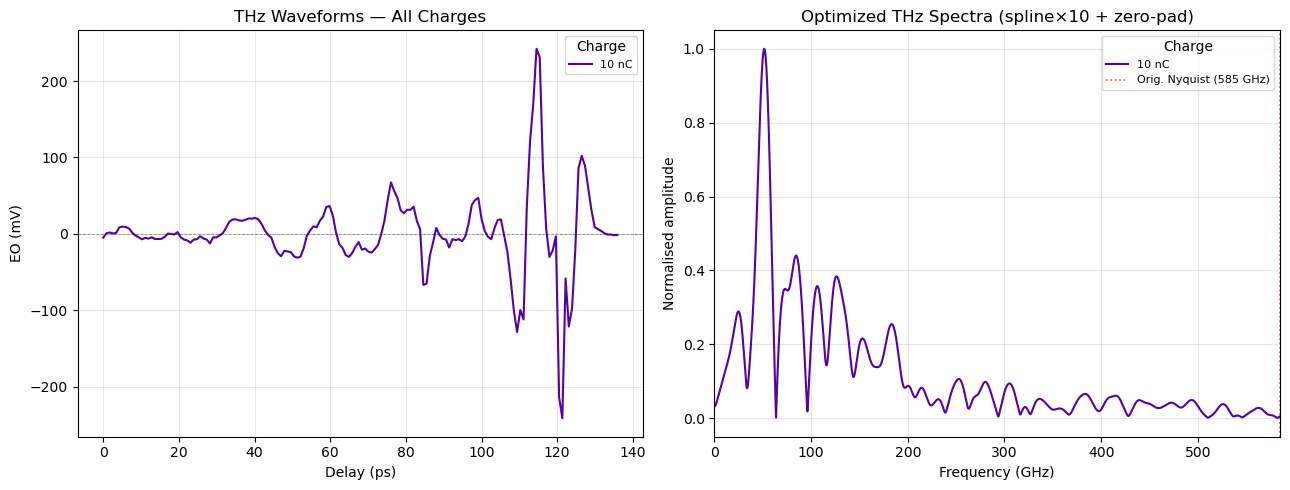

In [16]:
colors = plt.cm.plasma(np.linspace(0.15, 0.85, len(SCANS)))

fig, (ax_t, ax_f) = plt.subplots(1, 2, figsize=(13, 5))

f_nyq_min = np.inf   # track tightest original-grid Nyquist across scans

for s, col in zip(SCANS, colors):
    dp_s, sig_s = get_signal(s['path'])
    n_s   = len(sig_s)
    dt_ps_s = (dp_s[-1]-dp_s[0])/(n_s-1)
    f_nyq_min = min(f_nyq_min, 0.5/dt_ps_s * 1e3)

    # Spline ×10
    up    = 10
    dp_up = np.linspace(dp_s[0], dp_s[-1], n_s*up)
    cs    = CubicSpline(dp_s, sig_s)
    sig_up = cs(dp_up) * np.hanning(n_s*up)

    # Zero-pad to next power of 2
    N_fft = 4**int(np.ceil(np.log2(len(sig_up))))
    N_pad = (N_fft - len(sig_up)) // 2
    padded = np.concatenate([np.zeros(N_pad), sig_up, np.zeros(N_fft-len(sig_up)-N_pad)])

    F   = np.abs(np.fft.rfft(padded))
    f   = np.fft.rfftfreq(len(padded), d=dt_ps_s*1e-12/up)/1e9

    ax_t.plot(dp_s, mV*sig_s, color=col, lw=1.5, label=s['label'])
    ax_f.plot(f, F/F.max(), color=col, lw=1.5, label=s['label'])

ax_t.axhline(0, color='k', lw=0.6, ls='--', alpha=0.4)
ax_t.set_xlabel('Delay (ps)'); ax_t.set_ylabel('EO (mV)')
ax_t.set_title('THz Waveforms — All Charges'); ax_t.legend(title='Charge',fontsize=8); ax_t.grid(True,alpha=0.3)

ax_f.axvline(f_nyq_min, color='red', ls=':', lw=1.2, alpha=0.7,
             label=f'Orig. Nyquist ({f_nyq_min:.0f} GHz)')
ax_f.set_xlabel('Frequency (GHz)'); ax_f.set_ylabel('Normalised amplitude')
ax_f.set_title('Optimized THz Spectra (spline×10 + zero-pad)')
ax_f.set_xlim(0, f_nyq_min); ax_f.legend(title='Charge',fontsize=8); ax_f.grid(True,alpha=0.3)

plt.tight_layout()
plt.savefig('Results/FFT_optimized_all_charges.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
# ── Peak frequency, centroid, and −3 dB (power) BW for optimized spectra ─────
# −3 dB power = amplitude / √2. BW is the contiguous half-power span around the peak,
# with sub-bin linear interpolation at the threshold crossings (otherwise BW
# is quantised to Δf ≈ 5–8 GHz and tells us nothing about the actual FWHM).
def fwhm_around_peak(f, F):
    thr  = F.max() / np.sqrt(2)
    i_pk = F.argmax()
    # walk left
    i_lo = i_pk
    while i_lo > 0 and F[i_lo-1] >= thr:
        i_lo -= 1
    if i_lo > 0:                                                    # interp between (i_lo-1, i_lo)
        a, b = F[i_lo-1], F[i_lo]
        f_lo = f[i_lo-1] + (thr - a)/(b - a) * (f[i_lo] - f[i_lo-1])
    else:
        f_lo = f[0]
    # walk right
    i_hi = i_pk
    while i_hi < len(F)-1 and F[i_hi+1] >= thr:
        i_hi += 1
    if i_hi < len(F)-1:                                             # interp between (i_hi, i_hi+1)
        a, b = F[i_hi], F[i_hi+1]
        f_hi = f[i_hi] + (a - thr)/(a - b) * (f[i_hi+1] - f[i_hi])
    else:
        f_hi = f[-1]
    return f_hi - f_lo

print(f"{'Charge':>8} | {'Peak freq (GHz)':>15} | {'Centroid (GHz)':>14} | {'-3dB BW (GHz)':>13}")
print('-' * 62)
for s in SCANS:
    dp_s, sig_s = get_signal(s['path'])
    n_s   = len(sig_s); dt_ps_s = (dp_s[-1]-dp_s[0])/(n_s-1)
    up=10; dp_up=np.linspace(dp_s[0],dp_s[-1],n_s*up)
    cs=CubicSpline(dp_s,sig_s); sig_up=cs(dp_up)*np.hanning(n_s*up)
    N_fft=2**int(np.ceil(np.log2(len(sig_up)))); N_pad=(N_fft-len(sig_up))//2
    padded=np.concatenate([np.zeros(N_pad),sig_up,np.zeros(N_fft-len(sig_up)-N_pad)])
    F=np.abs(np.fft.rfft(padded)); f=np.fft.rfftfreq(len(padded),d=dt_ps_s*1e-12/up)/1e9

    mask=f>5
    peak_f   = f[F.argmax()]
    centroid = (f[mask]*F[mask]).sum()/F[mask].sum()
    bw       = fwhm_around_peak(f, F)

    print(f"{s['label']:>8} | {peak_f:15.1f} | {centroid:14.1f} | {bw:13.1f}")


  Charge | Peak freq (GHz) | Centroid (GHz) | -3dB BW (GHz)
--------------------------------------------------------------
   10 nC |            51.4 |          162.6 |          11.1
